**Metodo BRIEF**\
Grupo 04\
Integrantes:
* Flores Baldoceda, Andres Francisco    20257600E
* Lazo Pampa, Victor Raul               20257639I
* Lopez Mendoza, Ruben                  20257664C
* Quispe Huanca, Juan Christian         20257661D

Paper: 
* "BRIEF: Binary Robust Independent Elementary Features" \
URL: https://link.springer.com/chapter/10.1007/978-3-642-15561-1_56

Data: 
* Trees (Blur), Graffiti (Viewpoint), Wall (Viewpoint), Ubc (JPEG Compression), Leuven (Light) \
https://www.robots.ox.ac.uk/~vgg/research/affine/

* Fountain (Viewpoint)
**PFL CVLAB Multi-View Dataset** (de Strecha et al.) \
https://github.com/openMVG/SfM_quality_evaluation/tree/348a981ef51112e9848acfb20004f4ed6fbc6ce3/Benchmarking_Camera_Calibration_2008/fountain-P11



Librerias

In [2]:
!pip install numpy
!pip install opencv-python
!pip install matplotlib

In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

np.random.seed(42)  # Para reproducibilidad de resultados

In [ ]:
# S = 31 # Tamaño del parche (debe ser impar)
# n_d = 256 # Número de comparaciones binarias
# estrategia = 'G_I' # Geometría de muestreo ('G\_I', 'G\_II', 'G\_III', 'G\_IV', 'G\_V')

In [4]:
def generate_brief_pairs(patch_size, num_pairs,strategy):  
    """ 
        Genera los pares de coordenadas relativas (X, Y) dentro del parche de imagen siguiendo las 5 geometrías de muestreo descritas en Calonder et al. (2010). 
    """
    
    S = patch_size
    n_d = num_pairs
    estrategia = strategy

    half_patch = S / 2.0
    # 
    
    # G I: Distribución Uniforme Continua U(-S/2, S/2)
    if strategy == 'G_I':
        # Generar coordenadas aleatorias dentro del parche
        X = np.random.uniform(-half_patch, half_patch, (num_pairs, 2))
        Y = np.random.uniform(-half_patch, half_patch, (num_pairs, 2))


    # G II: Distribución Gaussiana Isotrópica N(0, (S^2)/25) -&gt; sigma = S / 5
    elif strategy == 'G_II':
        sigma = S / 5.0
        X = np.random.normal(0, sigma, (num_pairs,2))
        Y = np.random.normal(0, sigma, (num_pairs,2))

    # G III: Gaussiana en 2 pasos -&gt; X \~ N(0, (S^2)/25), Y \~ N(X, (S^2)/100)
    elif strategy == 'G_III':
        sigma_X = S / 5.0
        sigma_Y = S / 10.0
        X = np.random.normal(0, sigma_X, (num_pairs,2))
        Y = np.random.normal(X, sigma_Y, (num_pairs,2))

    # G IV: Cuantización sobre grilla discreta
    elif strategy == 'G_IV':
        delta = 2
        grid_min = -int(half_patch//delta)
        grid_max = int(half_patch//delta) + 1

        X_grid =  np.random.randint(grid_min, grid_max, size=(num_pairs, 2))
        Y_grid =  np.random.randint(grid_min, grid_max, size=(num_pairs, 2))

        X = (X_grid * delta).astype(float)
        Y = (Y_grid * delta).astype(float)

    
    # G V: X fijo en el origen (0,0); Y en distribución polar uniforme
    elif strategy == 'G_V':
        X = np.zeros((num_pairs, 2))
        angles = np.random.uniform(0, 2 * np.pi, size = num_pairs)
        radii_Y = np.random.uniform(0, half_patch, size = num_pairs)
        Y = np.column_stack((radii_Y * np.cos(angles), radii_Y * np.sin(angles)))

    else:
        raise ValueError("Estrategia '{strategy}' no válida")

# Asegurar que las coordenadas estén dentro del parche
    X = np.clip(X, -half_patch + 1, half_patch - 1)
    Y = np.clip(Y, -half_patch + 1, half_patch - 1)

    return X, Y


class BRIEFExtractor:
    def __init__(self, patch_size, num_pairs, strategy, sigma, pairs=None):
        
        """ Inicializa el extractor BRIEF. 
        Args: 
            patch_size (int): Tamaño del parche S x S (por defecto 31). 
            num_pairs (int): Longitud del descriptor en bits n_d (128, 256 o 512). 
            strategy (str): Geometría de muestreo ('G_I' a 'G_V'). 
            
            Por defecto 'G_II'. sigma (float): Desviación estándar del filtro Gaussiano (por defecto 2.0).
     """

        self.patch_size = patch_size
        self.num_pairs = num_pairs
        self.strategy = strategy
        self.sigma = sigma
        self.half_S = patch_size // 2

        # Generar coordenadas de prueba y convertir a enteros para indexar píxeles

        #Reutilizar pares de coordenadas si se proporcionan, de lo contrario generarlos
        if pairs is not None:
            self.X, self.Y = pairs
        else:
            self.X, self.Y = generate_brief_pairs(patch_size, num_pairs, strategy)

        self.X_int = np.round(self.X).astype(int)
        self.Y_int = np.round(self.Y).astype(int)

    def compute (self, image, keypoints):
        """ 
        Calcula los descriptores binarios BRIEF para una lista de puntos clave. 
        """ 
        # Convertir a escala de grises si la imagen es a color
        if len(image.shape) == 3:
            gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        else:
            gray = image.copy()

        # 1. Pre-suavizado Gaussiano (kernel 9x9, sigma=2.0)
        
        if self.sigma <= 0:
            smoothed = gray
        else:
            smoothed = cv2.GaussianBlur(gray, (9, 9), self.sigma)

        h, w =gray.shape
        valid_keypoints = []
        descriptors = []

        for kp in keypoints:

            pt = kp.pt if isinstance(kp, cv2.KeyPoint) else kp
            cx, cy = int(round(pt[0])), int(round(pt[1]))

            # 2. Control de bordes: descartar puntos cercanos a los márgenes
            if (cx - self.half_S < 0 or cx + self.half_S >= w or
                cy - self.half_S < 0 or cy + self.half_S >= h):
                continue


            # 3. Muestreo de intensidades p(x) y p(y)
            # Indexación en NumPy (Fila = Y, Columna = X)
            val_X = smoothed[cy + self.X_int[:, 1], cx + self.X_int[:, 0]]
            val_Y = smoothed[cy + self.Y_int[:, 1], cx + self.Y_int[:, 0]]

            # 4. Prueba binaria tau: 1 si p(x) < p(y), sino 0
            bits = (val_X < val_Y).astype(np.uint8)

            # 5. Empaquetar bits a arreglo de bytes uint8 (ej. 256 bits -&gt; 32 bytes)
            
            descriptors.append(np.packbits(bits)) 
            valid_keypoints.append(kp) 
            
        if len(descriptors) == 0: 
            return [], np.array([], dtype=np.uint8)
        
        return valid_keypoints, np.array(descriptors, dtype=np.uint8)

        
                                                         

In [5]:
def hamming_distance(desc1, desc2): 
    
    """ 
        Calcula la distancia de Hamming mediante operación lógica XOR bit a bit y conteo de unos. 
    
    """ 
    xor_res = np.bitwise_xor(desc1, desc2) 
    
    if desc1.ndim == 1 and desc2.ndim == 1: 
        return np.sum([bin(byte).count('1') for byte in xor_res]) 
    
    return np.unpackbits(xor_res, axis=-1).sum(axis=-1)

In [8]:
def calcular_aciertos_homografia(matches, kp1, kp2, H, umbral_px=3.0):
    if len(matches) == 0:
        return 0
    correctos = 0
    for m in matches:
        # Coordenada homogénea [x, y, 1] en img1
        p1 = np.array([kp1[m.queryIdx].pt[0], kp1[m.queryIdx].pt[1], 1.0])
        p2 = np.array([kp2[m.trainIdx].pt[0], kp2[m.trainIdx].pt[1]])
        
        # Proyectar p1 a img2 usando la homografía H
        p1_proy = H @ p1 # Producto matricial
        p1_proy = p1_proy[:2] / p1_proy[2]
        
        # Si la distancia euclidiana es <= umbral, es un match correcto (inlier)
        if np.linalg.norm(p1_proy - p2) <= umbral_px:
            correctos += 1
    return correctos

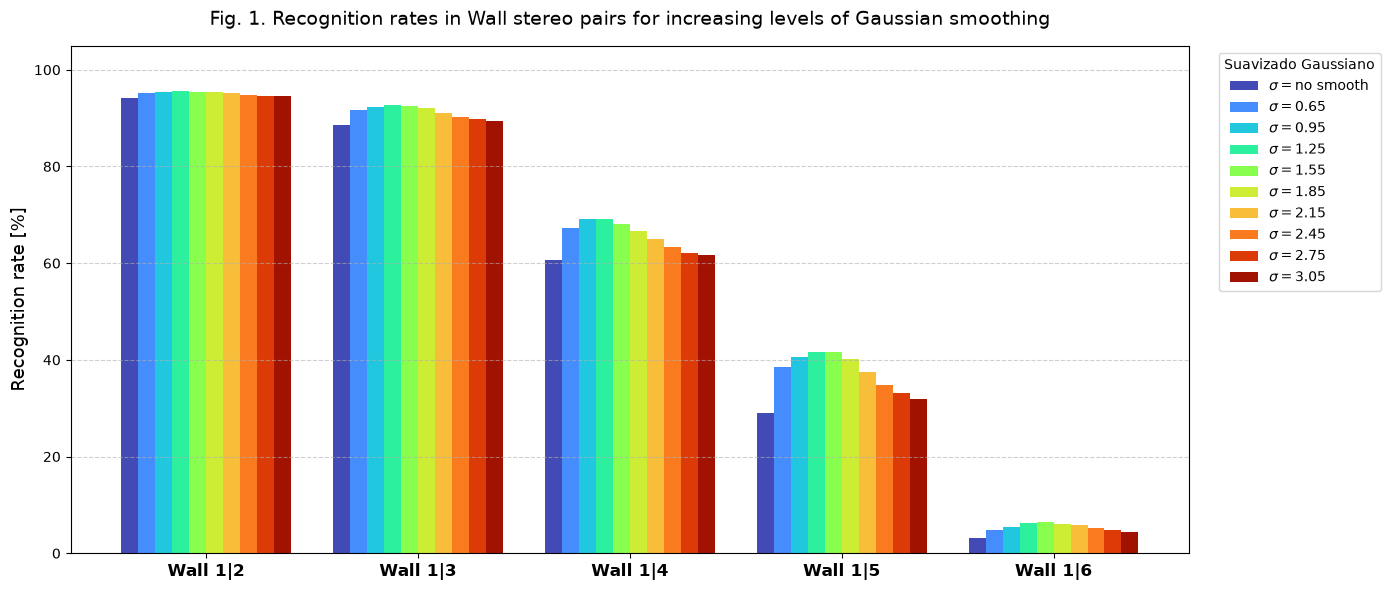

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Suavizado Gaussiano con la figura Wall 1 vs 2, 3, 4, 5 y 6

# 1. Cargar imágenes en escala de grises
img1 = cv2.imread('./images/Wall/img1.ppm', cv2.IMREAD_GRAYSCALE)
# img2 = cv2.imread('./images/Wall/img2.ppm', cv2.IMREAD_GRAYSCALE)

# 2. Dectectar puntos clave usando el detector FAST
fast = cv2.FastFeatureDetector_create(threshold=20)
kp1 = fast.detect(img1, None)
# kp2 = fast.detect(img2, None)

# Pares fijos para todas las pruebas de sigma
pairs = generate_brief_pairs(patch_size=31, num_pairs=256, strategy='G_II')
sigmas = [0, 0.65, 0.95, 1.25, 1.55, 1.85, 2.15, 2.45, 2.75, 3.05]
etiquetas_sigma = ['no smooth', '0.65', '0.95', '1.25', '1.55', '1.85', '2.15', '2.45', '2.75', '3.05']
# tasas_reconocimiento = []

# 3. Evaluar la tasa de reconocimiento para cada sigma
#    Emparejamiento de descriptores usando distancia de Hamming
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

# 2. Evaluar los 5 pares de imágenes (Wall 1|2 hasta Wall 1|6)
nombres_pares = [f'Wall 1|{i}' for i in range(2, 7)]
# Matriz para almacenar tasas: 5 pares x 10 sigmas
tasas_reconocimiento = np.zeros((len(nombres_pares), len(sigmas)))

# resultados_pares = {}

for row_idx, target_idx in enumerate(range(2, 7)):
    # nombre_par = f'Wall 1|{target_idx}'
    img_target = cv2.imread(f'./images/Wall/img{target_idx}.ppm', cv2.IMREAD_GRAYSCALE)

    H_gt = np.loadtxt(f'./images/Wall/H1to{target_idx}p')
    kp_target = fast.detect(img_target, None)

    # tasas_reconocimiento = []

    for col_idx, s in enumerate(sigmas):
        extractor = BRIEFExtractor(patch_size=31, num_pairs=256, strategy='G_II', sigma=s, pairs=pairs)

        v_kp1, d1 = extractor.compute(img1, kp1)
        v_kpt, dt = extractor.compute(img_target, kp_target)

    # 3. Emparejamiento de descriptores usando distancia de Hamming
        if len(d1) > 0 and len(dt) > 0:      
            matches = bf.match(d1, dt)
            correctos = calcular_aciertos_homografia(matches,v_kp1,v_kpt, H_gt, umbral_px=3.0)
            # Porcentaje de coincidencias correctas (tasa de reconocimiento)
            tasa = (correctos / len(matches)) * 100
            tasas_reconocimiento[row_idx, col_idx] = tasa
        else:
            tasas_reconocimiento[row_idx, col_idx] =0

    # resultados_pares[nombre_par] = tasas_reconocimiento

# 4. Grafico
fig, ax = plt.subplots(figsize=(14, 6))

num_pares = len(nombres_pares)
num_sigmas = len(sigmas)
x = np.arange(num_pares)
ancho_barra = 0.08

colores = plt.cm.turbo(np.linspace(0.08, 0.95, num_sigmas))

for j in range(num_sigmas):
    offset = (j-num_sigmas / 2 + 0.5) * ancho_barra
    ax.bar(x + offset, tasas_reconocimiento[:, j], width=ancho_barra, 
           label=r'$\sigma = $' + etiquetas_sigma[j], color=colores[j])

    # plt.plot(sigmas, tasas_reconocimiento, marker='o', label = nombre_par, linewidth = 1.8)

ax.set_ylabel('Recognition rate [%]', fontsize=13)
ax.set_title('Fig. 1. Recognition rates in Wall stereo pairs for increasing levels of Gaussian smoothing', fontsize=14, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(nombres_pares, fontsize=12, fontweight='bold')
ax.set_ylim(0, 105)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend(title='Suavizado Gaussiano', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

plt.tight_layout()
plt.show()